# ЛР 1 - дополнительный раунд

Ростислав Манзюк, grinchaus. Цель - приблизиться к macro-F1 0.70 при разделении по авторам.

Конфигурация выбрана на train с seed 42 и 137. Дополнительная проверка с seed 2026 выполнена после фиксации параметров. Test уже оценивался в предыдущих версиях; в этом раунде настройки зафиксированы до новой оценки.


In [1]:
import json
from pathlib import Path
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

root = Path.cwd()
results = root / "results/lab1-v3"
if not (results / "model.joblib").exists():
    subprocess.run([sys.executable, "run_lab1_v3.py", "--data", "data"], check=True)
metrics = json.loads((results / "metrics.json").read_text())
selection = metrics["selection"]
assert selection["test_used_for_selection"] is False
assert metrics["audit"]["used_for_selection"] is False
display(pd.DataFrame([{key: row[key] for key in ["macro_f1", "qwk", "accuracy"]} for row in metrics["test"].values()], index=metrics["test"].keys()))


,macro_f1,qwk,accuracy
selected_blend,0.6708,0.6175,0.7059
previous_v2,0.6593,0.6018,0.6916
official_baseline,0.5403,0.4603,0.5445


In [2]:
validation = pd.DataFrame({name: row["per_split"] for name, row in selection["candidates"].items()}, index=[42, 137]).T
validation.columns = ["seed 42 macro-F1", "seed 137 macro-F1"]
display(validation)
display(pd.DataFrame(selection["validation"]).T)
display(pd.DataFrame({name: metrics["audit"][name] for name in ["previous_v2", "selected_blend"]}).T)
display(pd.Series(selection["components"], name="ensemble weight"))


,seed 42 macro-F1,seed 137 macro-F1
v2,0.676584,0.672858
rich-multiclass,0.671458,0.668317
rich-ordinal,0.672320,0.671186
rich-regression,0.675403,0.668422
kernel-multiclass,0.674485,0.668979
graph-text,0.646116,0.641465
network,0.673495,0.668486
vision,0.674410,0.672244
qwen-vision,0.678675,0.671765
qwen-depth6,0.675842,0.669989


,macro_f1,qwk,accuracy
42,0.6866,0.6346,0.7165
137,0.6818,0.6263,0.7160


,macro_f1,qwk,accuracy
previous_v2,0.6611,0.6088,0.6924
selected_blend,0.6731,0.6237,0.7059


v2                           0.432
rich-regression              0.388
multimodal-dense-ensemble    0.180
Name: ensemble weight, dtype: float64

Сравниваются обычная классификация, две границы классов, регрессия отклонения, история похожих текстов и изображений, графовые признаки и фиксированные encoder E5, Qwen и CLIP. Статистика графа исключает весь вклад оцениваемого автора. История читает только более ранние посты. PCA, словари и масштабирование обучаются только на fit-авторах.


,precision,recall,f1-score,support
below,0.565688,0.560576,0.563121,3541.000000
typical,0.751403,0.765513,0.758393,10491.000000
above,0.707531,0.675021,0.690894,3591.000000
accuracy,0.705896,0.705896,0.705896,0.705896
macro avg,0.674874,0.667037,0.670802,17623.000000
weighted avg,0.705148,0.705896,0.705402,17623.000000


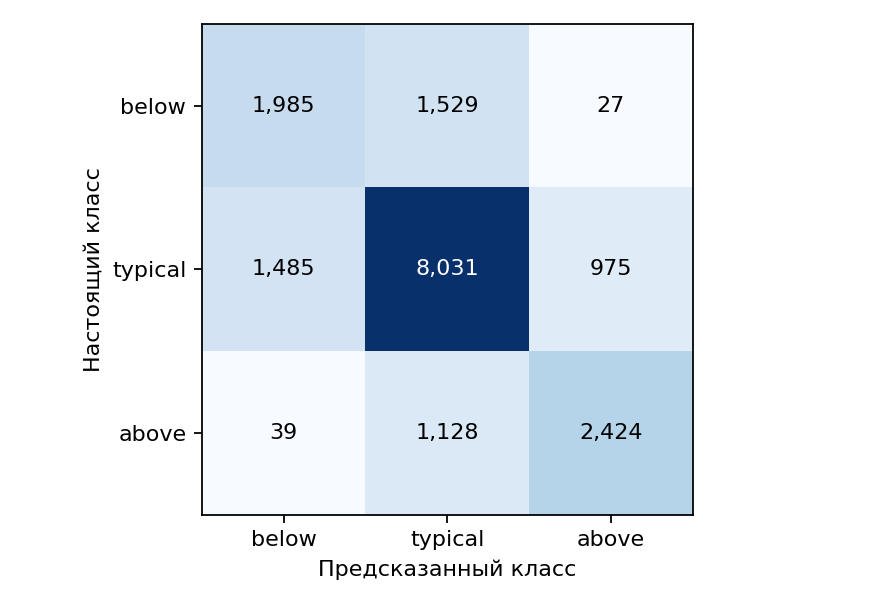

95% CI: [0.6616, 0.6802]
Comparison with frozen V2: {'previous_macro_f1': 0.6593, 'delta_macro_f1': 0.0115, 'paired_delta_95ci': [0.0073, 0.0159]}


In [3]:
display(pd.DataFrame(metrics["test"]["selected_blend"]["classification_report"]).T)
display(Image(filename=str(results / "confusion_matrix.png")))
print("95% CI:", metrics["confidence_intervals"]["macro_f1_95ci"]["selected_blend"])
print("Comparison with frozen V2:", metrics["previous_comparison"])


In [4]:
reproduced = results / "notebook-reproduced.csv"
check = subprocess.run([sys.executable, "predict_lab1_v3.py", "--data", "data", "--model", str(results / "model.joblib"), "--output", str(reproduced)], capture_output=True, text=True)
if check.returncode:
    raise RuntimeError(check.stdout + check.stderr)
expected = pd.read_csv(results / "selected_blend.csv")
actual = pd.read_csv(reproduced)
pd.testing.assert_frame_equal(expected, actual)
assert len(actual) == 17623 and not actual.duplicated(["author", "post"]).any()
assert actual.label.isin([0, 1, 2]).all()
print("Reloaded model: exact CSV equality, 17 623 unique test posts")


Reloaded model: exact CSV equality, 17 623 unique test posts


In [5]:
check = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-q"], capture_output=True, text=True)
if check.returncode:
    raise RuntimeError(check.stdout + check.stderr)
print("\n".join(check.stderr.strip().splitlines()[-4:]))


----------------------------------------------------------------------
Ran 34 tests in 2.406s

OK


Реакции и профиль - снимки на момент сбора. Более ранние реакции test-автора используются так же, как в официальном baseline. Это офлайн-оценка, её нельзя переносить напрямую на момент публикации. Разбиения валидации пересекаются и не являются независимыми тестами.

Полное воспроизведение из корня репозитория: `python run_lab1_v3.py --data data`. Процесс контролирует память, запускает тяжёлые этапы последовательно и передаёт на GPU отдельные батчи. Данные, пароли и веса моделей исключены из Git.
